[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\User\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\User\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\User\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\User\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


15 найчастіших слів:
Слово                Частота
------------------------------
product              6
quality              4
excellent            3
delivery             3
works                2
support              2
easy                 2
good                 2
customer             2
perfectly            1
great                1
fast                 1
friendly             1
really               1
like                 1


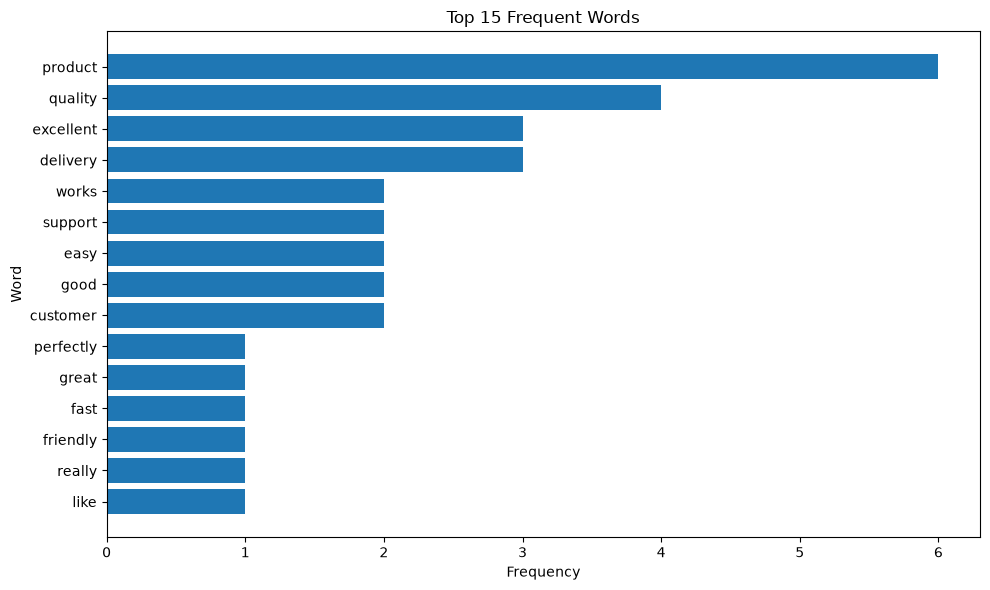


Графік збережено у feedback_word_freq.png.


In [1]:
# Завдання 3. Частотний словник і візуалізація

import re
from collections import Counter

import pandas as pd
import nltk
import matplotlib.pyplot as plt
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")

df = pd.read_csv("feedback.csv")
stop_words = set(stopwords.words("english"))

def clean_text(text):
    text = text.lower()
    text = re.sub(r"\d+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

all_tokens = []

for review in df["feedback"].dropna():
    tokens = word_tokenize(clean_text(review))
    filtered_tokens = [
        token for token in tokens
        if token not in stop_words and len(token) >= 4
    ]
    all_tokens.extend(filtered_tokens)

# Підрахунок частоти кожного слова
word_counts = Counter(all_tokens)
top_15 = word_counts.most_common(15)

print("15 найчастіших слів:")
print(f"{'Слово':<20} Частота")
print("-" * 30)
for word, frequency in top_15:
    print(f"{word:<20} {frequency}")

# Горизонтальна діаграма
words = [item[0] for item in top_15]
frequencies = [item[1] for item in top_15]

plt.figure(figsize=(10, 6))
plt.barh(words[::-1], frequencies[::-1])
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.title("Top 15 Frequent Words")
plt.tight_layout()

# Збереження графіка
plt.savefig("feedback_word_freq.png", dpi=300, bbox_inches="tight")
plt.show()

print("\nГрафік збережено у feedback_word_freq.png.")
